<a href="https://colab.research.google.com/github/adukirdat/deep_learning/blob/main/Perceptron_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perceptron from Scratch

## Step 1: Prepare the AND Gate Dataset

In this notebook, we will implement a perceptron from scratch and train it to learn the AND logical operation.

In [1]:
import numpy as np

# Input data
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# Expected output for AND gate
y = np.array([0, 0, 0, 1])

print("Input data:")
print(X)

print("Expected output:")
print(y)

Input data:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
Expected output:
[0 0 0 1]


In [2]:
def initialize_weights(n_features):
    weights = np.zeros(n_features)
    bias = 0
    return weights, bias

In [3]:
weights, bias = initialize_weights(2)

print("Initial weights:", weights)
print("Initial bias:", bias)

Initial weights: [0. 0.]
Initial bias: 0


In [4]:
def step_function(z):
    return 1 if z >= 0 else 0

In [5]:
print(step_function(-2))
print(step_function(0))
print(step_function(3))

0
1
1


In [6]:
def predict(x, weights, bias):
    z = np.dot(x, weights) + bias
    return step_function(z)

In [7]:
print(predict([0, 0], weights, bias))
print(predict([1, 1], weights, bias))

1
1


In [8]:
def update_weights(weights, bias, xi, target, prediction, learning_rate):
    error = target - prediction

    weights += learning_rate * error * xi
    bias += learning_rate * error

    return weights, bias

In [9]:
weights_test = np.zeros(2)
bias_test = 0

weights_test, bias_test = update_weights(
    weights_test, bias_test,
    np.array([1, 1]), 1, 0, 0.1
)

print("Updated weights:", weights_test)
print("Updated bias:", bias_test)

Updated weights: [0.1 0.1]
Updated bias: 0.1


In [10]:
def train_perceptron(X, y, learning_rate=0.1, epochs=10):
    n_samples, n_features = X.shape

    weights, bias = initialize_weights(n_features)

    for epoch in range(epochs):
        for xi, target in zip(X, y):
            prediction = predict(xi, weights, bias)

            weights, bias = update_weights(
                weights, bias,
                xi, target, prediction, learning_rate
            )

    return weights, bias

In [11]:
weights_and, bias_and = train_perceptron(X, y)

print("Trained weights:", weights_and)
print("Trained bias:", bias_and)

Trained weights: [0.2 0.1]
Trained bias: -0.20000000000000004


In [12]:
for xi in X:
    prediction = predict(xi, weights_and, bias_and)
    print(xi, "->", prediction)

[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1


In [13]:
predictions = []

for xi in X:
    prediction = predict(xi, weights_and, bias_and)
    predictions.append(prediction)

print("Actual outputs:   ", y)
print("Predicted outputs:", predictions)

correct = np.sum(y == predictions)
accuracy = (correct / len(y)) * 100

print("Accuracy:", accuracy, "%")

Actual outputs:    [0 0 0 1]
Predicted outputs: [0, 0, 0, 1]
Accuracy: 100.0 %


In [14]:
# OR gate dataset
y_or = np.array([0, 1, 1, 1])

# Train the perceptron
weights_or, bias_or = train_perceptron(X, y_or)

# Test predictions
predictions_or = []

for xi in X:
    prediction = predict(xi, weights_or, bias_or)
    predictions_or.append(prediction)

print("Actual outputs:   ", y_or)
print("Predicted outputs:", predictions_or)

Actual outputs:    [0 1 1 1]
Predicted outputs: [0, 1, 1, 1]


In [15]:
# XOR gate dataset
y_xor = np.array([0, 1, 1, 0])

# Train the perceptron
weights_xor, bias_xor = train_perceptron(X, y_xor)

# Test predictions
predictions_xor = []

for xi in X:
    prediction = predict(xi, weights_xor, bias_xor)
    predictions_xor.append(prediction)

print("Actual outputs:   ", y_xor)
print("Predicted outputs:", predictions_xor)

Actual outputs:    [0 1 1 0]
Predicted outputs: [1, 1, 0, 0]


In [16]:
correct_xor = np.sum(y_xor == predictions_xor)
accuracy_xor = (correct_xor / len(y_xor)) * 100

print("Correct predictions:", correct_xor)
print("Accuracy:", accuracy_xor, "%")

Correct predictions: 2
Accuracy: 50.0 %


## What I Learned

- A single-layer perceptron can learn AND and OR logical gates.
- XOR is not linearly separable.
- A single-layer perceptron cannot correctly classify all XOR inputs.
- Hidden layers and non-linear activation functions allow neural networks to learn more complex patterns.

In [17]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [18]:
print(sigmoid(0))
print(sigmoid(5))
print(sigmoid(-5))

0.5
0.9933071490757153
0.0066928509242848554


In [19]:
np.random.seed(42)

W1 = np.random.randn(2, 2)
b1 = np.zeros((1, 2))

W2 = np.random.randn(2, 1)
b2 = np.zeros((1, 1))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (2, 2)
b1 shape: (1, 2)
W2 shape: (2, 1)
b2 shape: (1, 1)


In [20]:
import matplotlib.pyplot as plt

In [21]:
plot_decision_boundary(
    X, y, weights_and, bias_and,
    "Perceptron - AND Gate"
)

NameError: name 'plot_decision_boundary' is not defined

In [22]:
def plot_decision_boundary(X, y, weights, bias, title):
    x_min, x_max = -0.5, 1.5
    y_min, y_max = -0.5, 1.5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.01),
        np.arange(y_min, y_max, 0.01)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = np.array([
        step_function(np.dot(x, weights) + bias)
        for x in grid
    ])

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(5, 4))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

    class_0 = X[y == 0]
    class_1 = X[y == 1]

    plt.scatter(
        class_0[:, 0], class_0[:, 1],
        color="blue", edgecolors="k", label="0"
    )
    plt.scatter(
        class_1[:, 0], class_1[:, 1],
        color="red", edgecolors="k", label="1"
    )

    plt.legend(title="Output Class", fontsize=8)
    plt.title(title)
    plt.xlabel("x₁")
    plt.ylabel("x₂")
    plt.grid(True)
    plt.show()

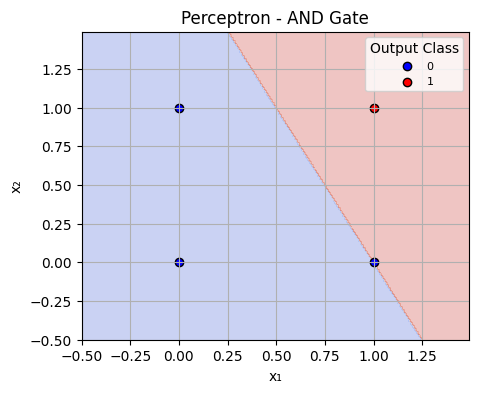

In [23]:
plot_decision_boundary(
    X, y, weights_and, bias_and,
    "Perceptron - AND Gate"
)

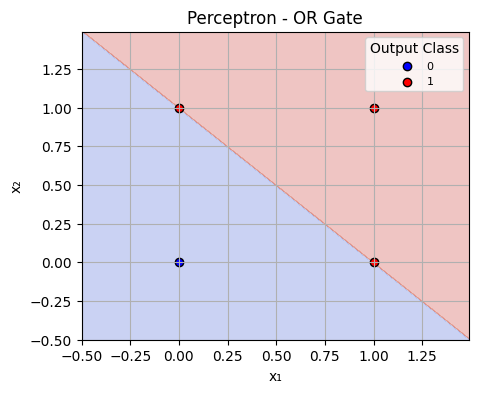

In [24]:
plot_decision_boundary(
    X, y_or, weights_or, bias_or,
    "Perceptron - OR Gate"
)